In [1]:
import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv('spam.csv',encoding='latin1')

In [3]:
df

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
...,...,...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
5568,ham,Will Ì_ b going to esplanade fr home?,NaN,NaN,NaN
5569,ham,"Pity, * was in mood for that. So...any other s...",NaN,NaN,NaN
5570,ham,The guy did some bitching but I acted like i'd...,NaN,NaN,NaN


In [4]:
df.shape

(5572, 5)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [6]:
df=df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'])

In [7]:
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [8]:
df.rename(columns={'v1':'target','v2':'text'},inplace=True)

In [9]:
df.head()

,target,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [10]:
from sklearn.preprocessing import LabelEncoder

In [11]:
encoder=LabelEncoder()

In [12]:
df['target']=encoder.fit_transform(df['target'])

In [13]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [14]:
# missing values

df.isnull().sum()

target    0
text      0
dtype: int64

In [15]:
# check duplicate

df.duplicated().sum()

np.int64(403)

In [16]:
# remove duplicate

df.drop_duplicates(keep='first',inplace=True)

In [17]:
df.shape

(5169, 2)

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
# EDA

In [20]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [21]:
df['target'].value_counts()


target
0    4516
1     653
Name: count, dtype: int64

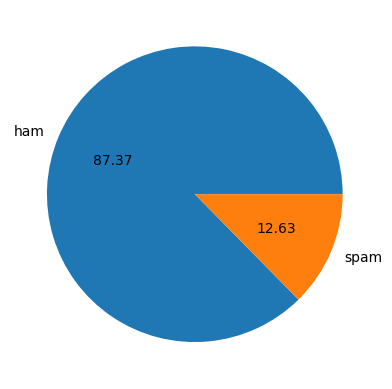

In [22]:
import matplotlib.pyplot as plt

plt.pie(df['target'].value_counts(),labels=('ham','spam'),autopct='%0.2f')
plt.show()

In [23]:
import nltk

In [24]:
!pip install nltk


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\91811\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [26]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [27]:
from nltk.tokenize import word_tokenize,sent_tokenize

In [28]:
def func(text):
 sentence=nltk.word_tokenize(text)
 return(len(sentence))

In [29]:
df['num_word']=df['text'].apply(func)

In [30]:
df

,target,text,num_word
0,0,"Go until jurong point, crazy.. Available only ...",24
1,0,Ok lar... Joking wif u oni...,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,37
3,0,U dun say so early hor... U c already then say...,13
4,0,"Nah I don't think he goes to usf, he lives aro...",15
...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,35
5568,0,Will Ì_ b going to esplanade fr home?,9
5569,0,"Pity, * was in mood for that. So...any other s...",15
5570,0,The guy did some bitching but I acted like i'd...,27


In [31]:
df['num_character']=df['text'].apply(len)

In [32]:
def cal(text):
    sentences=nltk.sent_tokenize(text)
    return len(sentences)

In [33]:
df['num_sentences']=df['text'].apply(cal)

In [34]:
df.head()

,target,text,num_word,num_character,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",24,111,2
1,0,Ok lar... Joking wif u oni...,8,29,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,37,155,2
3,0,U dun say so early hor... U c already then say...,13,49,1
4,0,"Nah I don't think he goes to usf, he lives aro...",15,61,1


In [35]:
df[['num_word','num_character','num_sentences']].describe()

,num_word,num_character,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,18.460437,78.977945,1.965564
std,13.334441,58.236293,1.448541
min,1.000000,2.000000,1.000000
25%,9.000000,36.000000,1.000000
50%,15.000000,60.000000,1.000000
75%,26.000000,117.000000,2.000000
max,220.000000,910.000000,38.000000


In [36]:
df[df['target']==1][['num_word','num_character','num_sentences']].describe() # spam

,num_word,num_character,num_sentences
count,653.000000,653.000000,653.000000
mean,27.672282,137.891271,2.970904
std,7.010932,30.137753,1.488425
min,2.000000,13.000000,1.000000
25%,25.000000,132.000000,2.000000
50%,29.000000,149.000000,3.000000
75%,32.000000,157.000000,4.000000
max,46.000000,224.000000,9.000000


In [37]:
df[df['target']==0][['num_word','num_character','num_sentences']].describe() #ham

,num_word,num_character,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,17.128432,70.459256,1.820195
std,13.504730,56.358207,1.383657
min,1.000000,2.000000,1.000000
25%,8.000000,34.000000,1.000000
50%,13.000000,52.000000,1.000000
75%,22.000000,90.000000,2.000000
max,220.000000,910.000000,38.000000


<Axes: xlabel='num_word', ylabel='Count'>

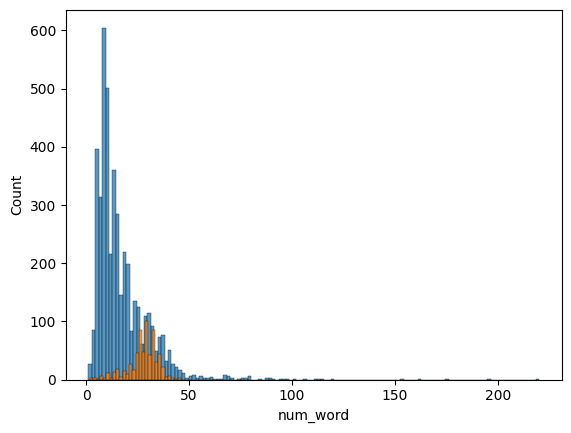

In [38]:
import seaborn as sns
sns.histplot(df[df['target']==0]['num_word'])
sns.histplot(df[df['target']==1]['num_word'])

<Axes: xlabel='num_character', ylabel='Count'>

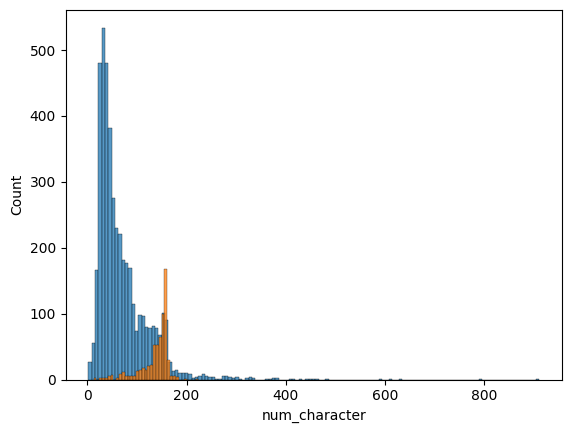

In [39]:
import seaborn as sns
sns.histplot(df[df['target']==0]['num_character'])
sns.histplot(df[df['target']==1]['num_character'])

<Axes: xlabel='num_sentences', ylabel='Count'>

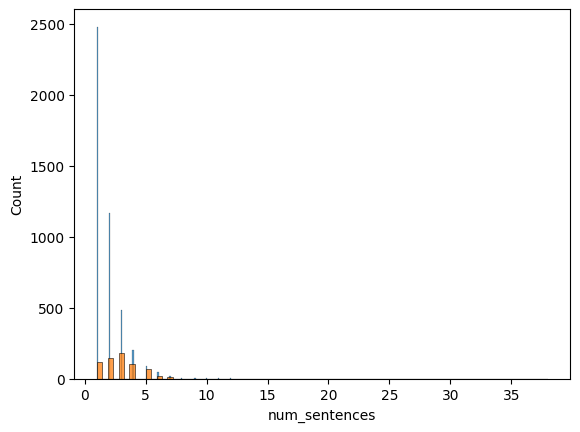

In [40]:
import seaborn as sns
sns.histplot(df[df['target']==0]['num_sentences'])
sns.histplot(df[df['target']==1]['num_sentences'])

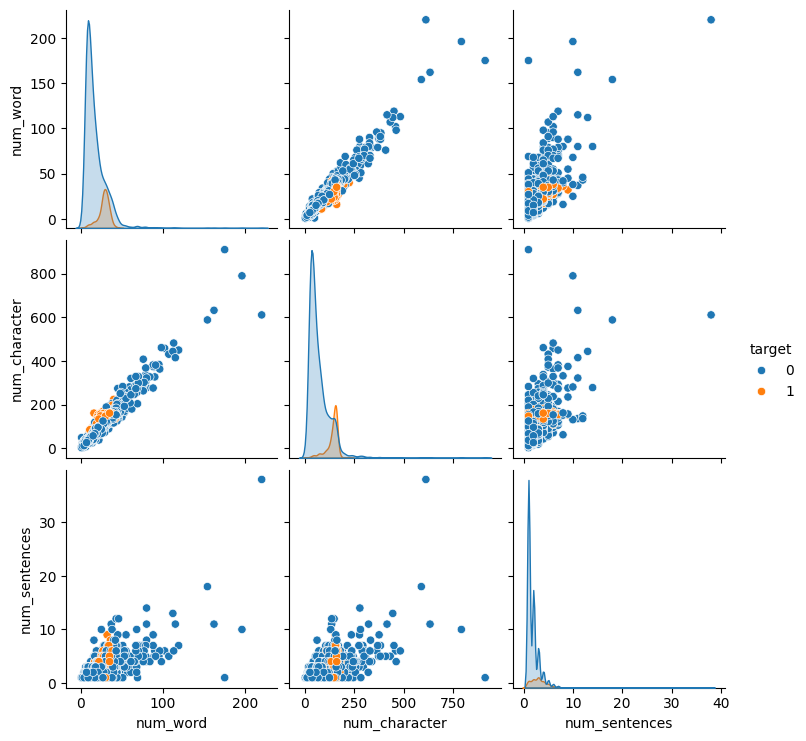

In [41]:
import seaborn as sns
sns.pairplot(df,hue='target')

<Axes: >

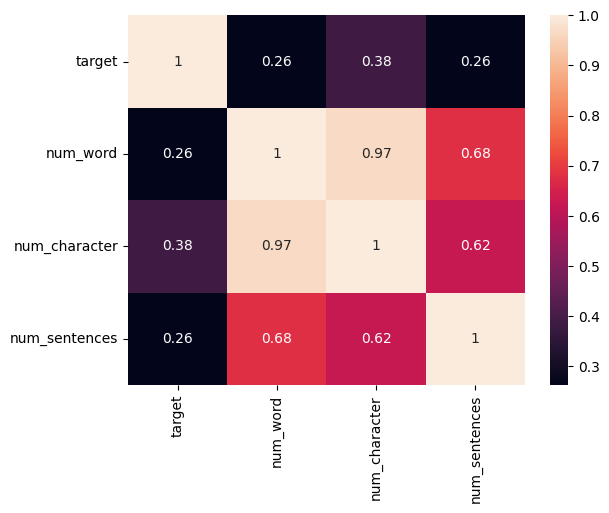

In [42]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [43]:
# Data preprocessing

In [44]:
import re
from nltk.corpus import stopwords

In [45]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\91811\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [46]:
stop_words=set(stopwords.words('english'))

In [47]:
def sentences(text):
    text=text.lower()

    text=re.sub(r'<.*?>','',text)

    text=re.sub(r'[^\w\s]','',text)

    text=re.sub(r'\d+','',text)
    filtering_words=[]
    for word in text.split():
        if word not in stop_words:
            filtering_words.append(word)

    text='  '.join(filtering_words)
    return text

In [48]:
df['transformed_text']=df['text'].apply(sentences)

In [49]:
df.head()

,target,text,num_word,num_character,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",24,111,2,go jurong point crazy available bugis n ...
1,0,Ok lar... Joking wif u oni...,8,29,2,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,37,155,2,free entry wkly comp win fa cup final ...
3,0,U dun say so early hor... U c already then say...,13,49,1,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",15,61,1,nah dont think goes usf lives around th...


In [50]:
# stemming

from nltk.stem.porter import PorterStemmer

ps=PorterStemmer()

def fung(text):
    words=text.split()
    stemming_words=[]
    for word in words:
        stemming_words.append(ps.stem(word))
    return ' '.join(stemming_words)

In [51]:
df['transformed_text']=df['transformed_text'].apply(fung)

In [52]:
df.head()

,target,text,num_word,num_character,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",24,111,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,8,29,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,37,155,2,free entri wkli comp win fa cup final tkt st m...
3,0,U dun say so early hor... U c already then say...,13,49,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",15,61,1,nah dont think goe usf live around though


In [53]:
from wordcloud import WordCloud

wc=WordCloud(height=1000,width=1000,min_font_size=10,background_color='white')

In [54]:
spam_wc=wc.generate(df[df['target']==1]['transformed_text'].str.cat(sep=' '))

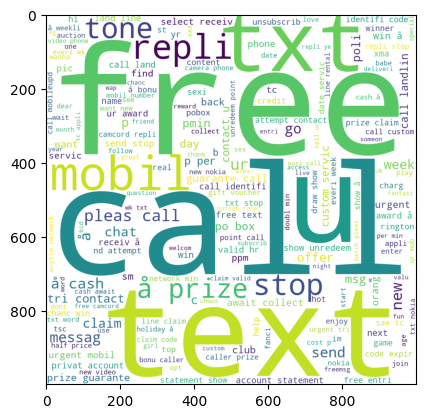

In [55]:
plt.imshow(spam_wc)

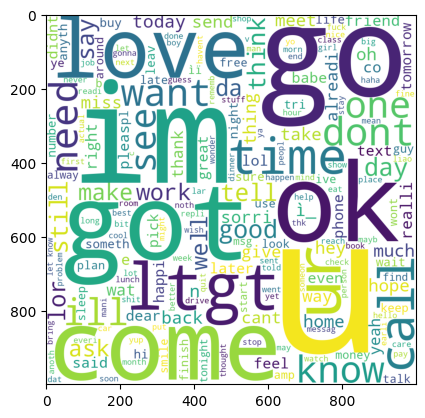

In [56]:
pam_wc=wc.generate(df[df['target']==0]['transformed_text'].str.cat(sep=' '))
plt.imshow(pam_wc)

In [57]:
spam_corpus=[]

for words in df[df['target']==1]['transformed_text'].tolist():
    for word in words.split():
      spam_corpus.append(word)

In [58]:
spam_corpus

['free',
 'entri',
 'wkli',
 'comp',
 'win',
 'fa',
 'cup',
 'final',
 'tkt',
 'st',
 'may',
 'text',
 'fa',
 'receiv',
 'entri',
 'questionstd',
 'txt',
 'ratetc',
 'appli',
 'over',
 'freemsg',
 'hey',
 'darl',
 'week',
 'word',
 'back',
 'id',
 'like',
 'fun',
 'still',
 'tb',
 'ok',
 'xxx',
 'std',
 'chg',
 'send',
 'å',
 'rcv',
 'winner',
 'valu',
 'network',
 'custom',
 'select',
 'receivea',
 'å',
 'prize',
 'reward',
 'claim',
 'call',
 'claim',
 'code',
 'kl',
 'valid',
 'hour',
 'mobil',
 'month',
 'u',
 'r',
 'entitl',
 'updat',
 'latest',
 'colour',
 'mobil',
 'camera',
 'free',
 'call',
 'mobil',
 'updat',
 'co',
 'free',
 'six',
 'chanc',
 'win',
 'cash',
 'pound',
 'txt',
 'csh',
 'send',
 'cost',
 'pday',
 'day',
 'tsandc',
 'appli',
 'repli',
 'hl',
 'info',
 'urgent',
 'week',
 'free',
 'membership',
 'å',
 'prize',
 'jackpot',
 'txt',
 'word',
 'claim',
 'tc',
 'wwwdbuknet',
 'lccltd',
 'pobox',
 'ldnwarw',
 'xxxmobilemovieclub',
 'use',
 'credit',
 'click',
 'wap',


In [59]:
len(spam_corpus)

9431

In [60]:
from collections import Counter
pd.DataFrame(Counter(spam_corpus).most_common(30))

,0,1
0,call,323
1,å,221
2,free,190
3,txt,137
4,u,130
5,text,122
6,ur,119
7,mobil,115
8,stop,106
9,repli,101


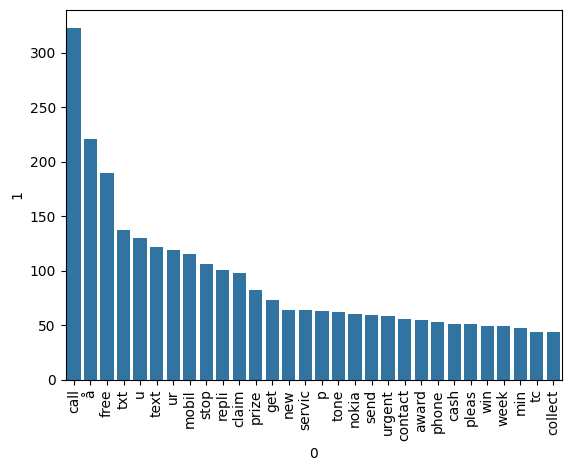

In [61]:
sns.barplot(x=pd.DataFrame(Counter(spam_corpus).most_common(30))[0],y=pd.DataFrame(Counter(spam_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

In [62]:
pam_corpus=[]

for words in df[df['target']==0]['transformed_text'].tolist():
    for word in words.split():
      pam_corpus.append(word)

In [63]:
pd.DataFrame(Counter(pam_corpus).most_common(30))

,0,1
0,u,890
1,im,437
2,go,403
3,get,354
4,come,272
5,ltgt,254
6,ok,246
7,dont,242
8,like,232
9,know,232


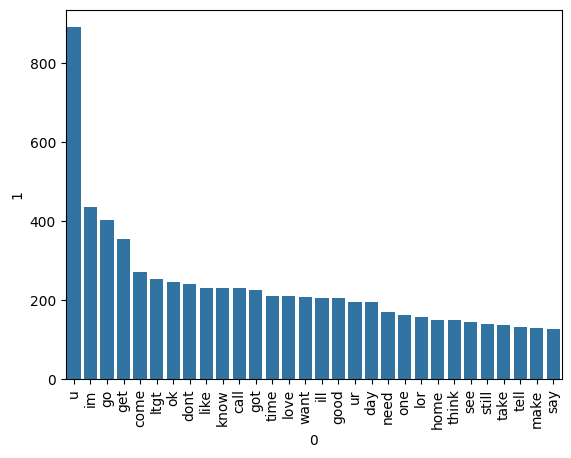

In [64]:
sns.barplot(x=pd.DataFrame(Counter(pam_corpus).most_common(30))[0],y=pd.DataFrame(Counter(pam_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

In [65]:
df

,target,text,num_word,num_character,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",24,111,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,8,29,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,37,155,2,free entri wkli comp win fa cup final tkt st m...
3,0,U dun say so early hor... U c already then say...,13,49,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",15,61,1,nah dont think goe usf live around though
...,...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,35,161,4,nd time tri contact u u å pound prize claim ea...
5568,0,Will Ì_ b going to esplanade fr home?,9,37,1,ì_ b go esplanad fr home
5569,0,"Pity, * was in mood for that. So...any other s...",15,57,2,piti mood soani suggest
5570,0,The guy did some bitching but I acted like i'd...,27,125,1,guy bitch act like id interest buy someth els ...


In [66]:
# Model building

In [67]:
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer

tfidf=TfidfVectorizer()
X=tfidf.fit_transform(df['transformed_text']).toarray()

In [68]:
X.shape

(5169, 7131)

In [69]:
y=df['target'].values

In [70]:
from sklearn.model_selection import train_test_split

In [71]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [72]:
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score

In [73]:
gnb=GaussianNB()
mnb=MultinomialNB()
bnb=BernoulliNB()

In [74]:
gnb.fit(X_train,y_train)
mnb.fit(X_train,y_train)
bnb.fit(X_train,y_train)

,alpha,1.0
,force_alpha,True
,binarize,0.0
,fit_prior,True
,class_prior,None


In [75]:
y_pred1=gnb.predict(X_test)
y_pred2=mnb.predict(X_test)
y_pred3=bnb.predict(X_test)

In [76]:
print(accuracy_score(y_test,y_pred1))
print(accuracy_score(y_test,y_pred2))
print(accuracy_score(y_test,y_pred3))

0.867504835589942
0.9613152804642167
0.9642166344294004


In [77]:
print(precision_score(y_test,y_pred1))
print(precision_score(y_test,y_pred2))
print(precision_score(y_test,y_pred3))

0.5173913043478261
1.0
0.95


In [78]:
print(confusion_matrix(y_test,y_pred1))
print(confusion_matrix(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred3))

[[778 111]
 [ 26 119]]
[[889   0]
 [ 40 105]]
[[883   6]
 [ 31 114]]


In [79]:
# Also try with another algorithm

In [80]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.naive_bayes import MultinomialNB

In [81]:
svc=SVC(kernel='sigmoid',gamma=1.0)
knc=KNeighborsClassifier()
mnb=MultinomialNB()
dtc=DecisionTreeClassifier(max_depth=5)
lrc=LogisticRegression(solver='liblinear',penalty='l1')
rfc=RandomForestClassifier(n_estimators=50,random_state=2)
abc=AdaBoostClassifier(n_estimators=50,random_state=2)
bc=BaggingClassifier(n_estimators=50,random_state=2)
etc=ExtraTreesClassifier(n_estimators=50,random_state=2)
gbdt=GradientBoostingClassifier(n_estimators=50,random_state=2)
xgb=XGBClassifier(n_estimators=50,random_state=2)

In [82]:
clfs={
    'SVC':svc,
    'KNC':knc,
    'MNB':mnb,
    'DTC':dtc,
    'LRC':lrc,
    'ABC':abc,
    'BC':bc,
    'ETC':etc,
    'GBDT':gbdt,
    'XGB':xgb,
    'RFC':rfc,
}

In [83]:
def train_classifier(clf,X_train,X_test,y_train,y_test):
   clf.fit(X_train,y_train)
   y_pred=clf.predict(X_test)
   accuracy=accuracy_score(y_test,y_pred)
   precision=precision_score(y_test,y_pred)
   return accuracy,precision

In [84]:
accuracy1=[]
precision1=[]


for name,clf in clfs.items():
    current_accuracy,current_precision=train_classifier(clf,X_train,X_test,y_train,y_test)
    print('Name :', name),
    print('Accuracy : ',current_accuracy),
    print('Precision : ',current_precision)
    
    accuracy1.append(current_accuracy)
    precision1.append(current_precision)

Name : SVC
Accuracy :  0.9729206963249516
Precision :  0.9398496240601504
Name : KNC
Accuracy :  0.9042553191489362
Precision :  1.0
Name : MNB
Accuracy :  0.9613152804642167
Precision :  1.0
Name : DTC
Accuracy :  0.9323017408123792
Precision :  0.8571428571428571
Name : LRC
Accuracy :  0.9448742746615088
Precision :  0.8928571428571429
Name : ABC
Accuracy :  0.9158607350096711
Precision :  0.7843137254901961
Name : BC
Accuracy :  0.9613152804642167
Precision :  0.8947368421052632
Name : ETC
Accuracy :  0.9690522243713733
Precision :  0.9829059829059829
Name : GBDT
Accuracy :  0.9497098646034816
Precision :  0.979381443298969
Name : XGB
Accuracy :  0.9690522243713733
Precision :  0.959349593495935
Name : RFC
Accuracy :  0.9671179883945842
Precision :  1.0


In [85]:
final=pd.DataFrame()

In [97]:
final['Classifier']=clfs.keys()
final['Accuracy']=accuracy1
final['Precision']=precision1

final.sort_values('Precision',ascending=False)

,Accuracy,Precision,Classifier
1,0.904255,1.000000,KNC
2,0.961315,1.000000,MNB
10,0.967118,1.000000,RFC
7,0.969052,0.982906,ETC
8,0.949710,0.979381,GBDT
9,0.969052,0.959350,XGB
0,0.972921,0.939850,SVC
6,0.961315,0.894737,BC
4,0.944874,0.892857,LRC
3,0.932302,0.857143,DTC


In [98]:
import pickle

pickle.dump(tfidf,open('vectorizer.pkl','wb'))
pickle.dump(mnb,open('model.pkl','wb'))